# Лабораторная работа 4. Бинарная классификация

**Студент:** Войтко Тимофей Дмитриевич, 351002

Цель — подготовить данные и сравнить логистическую регрессию, SVM и дерево решений CART для предсказания бинарного признака `is_healthy`.


## 1. Импорт библиотек и данных

Используем приложенный набор планов питания. `is_healthy` — бинарная целевая переменная: 1 означает здоровый план, 0 — иначе.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

DATA_PATH = Path("Healthy Meal Plan Dataset/healthy_meal_plans.csv")
RANDOM_STATE = 42
df = pd.read_csv(DATA_PATH)
print("Размер датасета:", df.shape)
display(df.head())
df.info()

Размер датасета: (500, 14)


,meal_name,num_ingredients,calories,prep_time,protein,fat,carbs,vegan,vegetarian,keto,paleo,gluten_free,mediterranean,is_healthy
0,Gluten-Free Pasta,0.272727,0.490909,0.84,0.783679,0.597907,0.444572,0,0,0,0,1,0,1
1,Grilled Salmon,0.909091,0.158182,0.70,0.143588,0.652082,0.050609,0,0,1,1,1,1,0
2,Lentil Soup,0.454545,0.700000,0.40,0.620637,0.612748,0.000688,0,1,0,0,0,0,0
3,Chickpea Stew,0.909091,0.105455,0.82,0.046893,0.975761,0.229026,1,1,0,0,0,0,0
4,Turkey Lettuce Wraps,0.181818,0.441818,0.04,0.864340,0.681575,0.449293,0,0,1,1,1,1,0


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   meal_name        500 non-null    str    
 1   num_ingredients  500 non-null    float64
 2   calories         500 non-null    float64
 3   prep_time        500 non-null    float64
 4   protein          500 non-null    float64
 5   fat              500 non-null    float64
 6   carbs            500 non-null    float64
 7   vegan            500 non-null    int64  
 8   vegetarian       500 non-null    int64  
 9   keto             500 non-null    int64  
 10  paleo            500 non-null    int64  
 11  gluten_free      500 non-null    int64  
 12  mediterranean    500 non-null    int64  
 13  is_healthy       500 non-null    int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 54.8 KB


## 2. Первичный анализ и очистка

Проверяем пропуски, дубликаты, диапазоны и баланс классов. Этот набор уже масштабирован в диапазон [0, 1], поэтому при очистке не нужно повторно нормализовать его значения. `meal_name` — текстовая метка с большим числом повторяющихся названий; исключим её из признаков, чтобы не усложнять модель и не вносить категориальную утечку.

Пропусков всего: 0
Полных дубликатов: 0
Баланс целевой переменной:


,count
is_healthy,
0,453
1,47


,count,mean,std,min,25%,50%,75%,max
num_ingredients,500.0,0.489818,0.305054,0.0,0.272727,0.454545,0.727273,1.0
calories,500.0,0.504149,0.290267,0.0,0.231818,0.509091,0.751364,1.0
prep_time,500.0,0.486480,0.293234,0.0,0.220000,0.490000,0.740000,1.0
protein,500.0,0.505704,0.291046,0.0,0.236392,0.521935,0.764155,1.0
fat,500.0,0.506822,0.282906,0.0,0.257945,0.516733,0.751306,1.0
carbs,500.0,0.507081,0.292257,0.0,0.251489,0.510196,0.746904,1.0
vegan,500.0,0.334000,0.472112,0.0,0.000000,0.000000,1.000000,1.0
vegetarian,500.0,0.574000,0.494989,0.0,0.000000,1.000000,1.000000,1.0
keto,500.0,0.366000,0.482192,0.0,0.000000,0.000000,1.000000,1.0
paleo,500.0,0.388000,0.487783,0.0,0.000000,0.000000,1.000000,1.0


Числовые признаки уже в [0, 1]: True


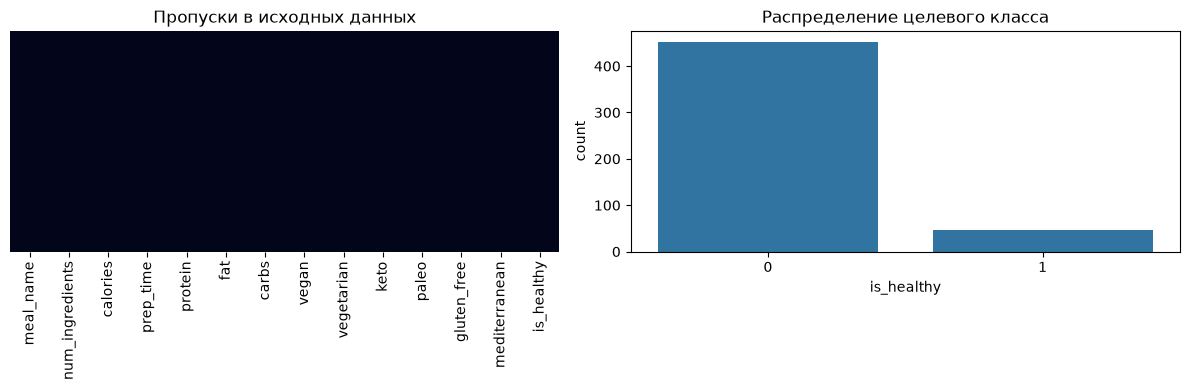

In [2]:
print("Пропусков всего:", int(df.isna().sum().sum()))
print("Полных дубликатов:", int(df.duplicated().sum()))
print("Баланс целевой переменной:")
display(df["is_healthy"].value_counts().rename_axis("is_healthy").to_frame("count"))
display(df.describe().T)

numeric_features = [column for column in df.select_dtypes(include=np.number).columns if column != "is_healthy"]
print("Числовые признаки уже в [0, 1]:", bool((df[numeric_features].min() >= 0).all() and (df[numeric_features].max() <= 1).all()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("Пропуски в исходных данных")
sns.countplot(data=df, x="is_healthy", ax=axes[1])
axes[1].set_title("Распределение целевого класса")
plt.tight_layout()
plt.show()

### Проверка выбросов

IQR используем как диагностику на признаках, которые не являются бинарными индикаторами. Поскольку значения датасета заранее ограничены диапазоном [0, 1], оценим потенциальные выбросы по числовым описательным статистикам и BoxPlot; удалять строки без оснований не будем, поскольку случайные крайние значения в синтетическом наборе сами по себе не являются ошибками измерения.

Потенциальные выбросы по IQR: {'num_ingredients': 0, 'calories': 0, 'prep_time': 0, 'protein': 0, 'fat': 0, 'carbs': 0}


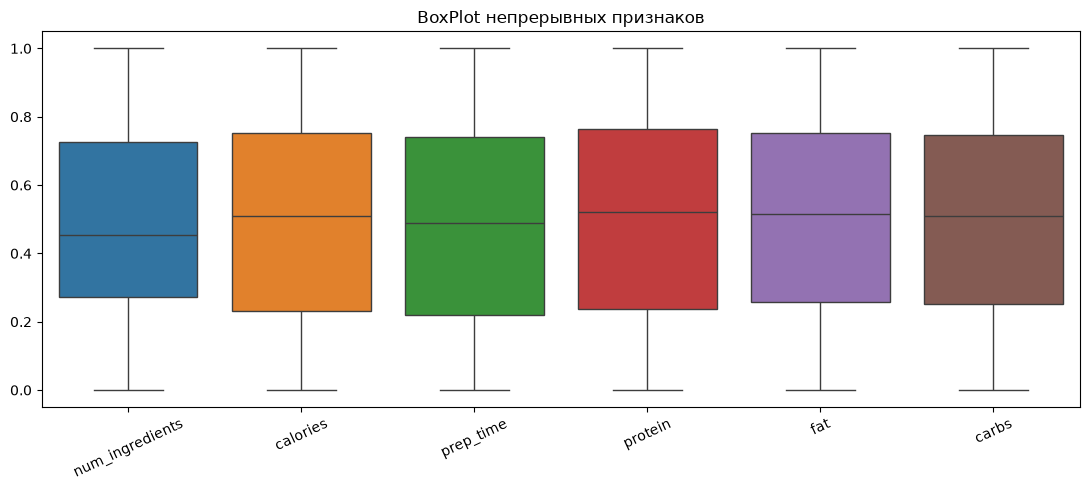

In [3]:
continuous_features = ["num_ingredients", "calories", "prep_time", "protein", "fat", "carbs"]
outlier_counts = {}
for column in continuous_features:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    outlier_counts[column] = int(((df[column] < q1 - 1.5 * iqr) | (df[column] > q3 + 1.5 * iqr)).sum())
print("Потенциальные выбросы по IQR:", outlier_counts)

plt.figure(figsize=(11, 5))
sns.boxplot(data=df[continuous_features])
plt.title("BoxPlot непрерывных признаков")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 3. Целевая переменная и признаки

Цель `y` — `is_healthy`. Признаки `X` — числовые характеристики и бинарные диетические признаки; целевой столбец и `meal_name` исключаются. Данные делятся стратифицированно, чтобы сохранить соотношение классов в train и test.

In [4]:
target = "is_healthy"
feature_columns = [column for column in df.columns if column not in [target, "meal_name"]]
X = df[feature_columns].copy()
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Признаки:", feature_columns)
print("Размер train/test:", X_train.shape, X_test.shape)
print("Доли положительного класса train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Признаки: ['num_ingredients', 'calories', 'prep_time', 'protein', 'fat', 'carbs', 'vegan', 'vegetarian', 'keto', 'paleo', 'gluten_free', 'mediterranean']
Размер train/test: (375, 12) (125, 12)
Доли положительного класса train/test: 0.093 0.096


## 4. Обучение трёх моделей

Для логистической регрессии и SVM добавим StandardScaler в Pipeline. Это важно, чтобы масштабирование обучалось только на train. Дереву CART масштабирование не требуется. Из-за редкого положительного класса зададим `class_weight='balanced'` у классификаторов, где это поддерживается.

In [5]:
models = {
    "Логистическая регрессия": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "CART": DecisionTreeClassifier(
        class_weight="balanced", max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
}

predictions = {}
probabilities = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        probabilities[name] = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)
        probabilities[name] = (scores - scores.min()) / (scores.max() - scores.min())
    print(name, "обучена")

Логистическая регрессия обучена
SVM обучена
CART обучена


## 5. Оценка качества

Accuracy может выглядеть высокой даже при игнорировании редкого класса. Поэтому дополнительно сравним precision, recall, F1 и ROC-AUC; особенно важны recall и F1 для класса 1.

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
SVM,0.840,0.357,0.833,0.500,0.912
CART,0.832,0.345,0.833,0.488,0.833
Логистическая регрессия,0.616,0.154,0.667,0.250,0.652


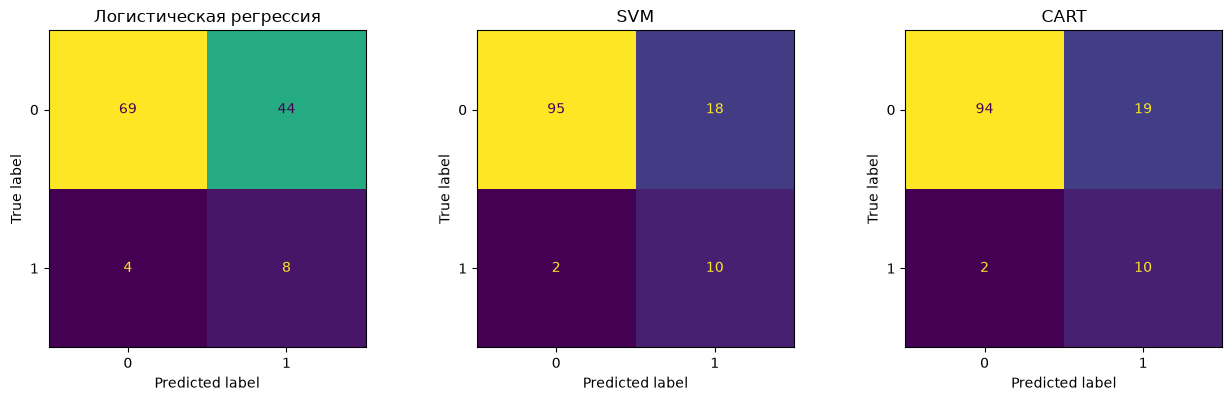

In [6]:
metric_rows = []
for name in models:
    metric_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predictions[name]),
        "Precision": precision_score(y_test, predictions[name], zero_division=0),
        "Recall": recall_score(y_test, predictions[name], zero_division=0),
        "F1": f1_score(y_test, predictions[name], zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities[name]),
    })
metrics = pd.DataFrame(metric_rows).set_index("Модель").sort_values("F1", ascending=False)
display(metrics.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axis, colorbar=False, values_format="d")
    axis.set_title(name)
plt.tight_layout()
plt.show()

## 6. Отчёты классификации и интерпретация CART

Матрица ошибок показывает правильные и ошибочные предсказания по каждому классу. Для дерева также выведем важности признаков и визуализируем его структуру.


 Логистическая регрессия
              precision    recall  f1-score   support

 не здоровый       0.95      0.61      0.74       113
    здоровый       0.15      0.67      0.25        12

    accuracy                           0.62       125
   macro avg       0.55      0.64      0.50       125
weighted avg       0.87      0.62      0.69       125


 SVM
              precision    recall  f1-score   support

 не здоровый       0.98      0.84      0.90       113
    здоровый       0.36      0.83      0.50        12

    accuracy                           0.84       125
   macro avg       0.67      0.84      0.70       125
weighted avg       0.92      0.84      0.87       125


 CART
              precision    recall  f1-score   support

 не здоровый       0.98      0.83      0.90       113
    здоровый       0.34      0.83      0.49        12

    accuracy                           0.83       125
   macro avg       0.66      0.83      0.69       125
weighted avg       0.92      0.83  

,importance
calories,4.248779e-01
fat,3.322910e-01
protein,2.428311e-01
vegetarian,6.520208e-15
num_ingredients,6.175021e-15
prep_time,0.000000e+00
carbs,0.000000e+00
vegan,0.000000e+00
keto,0.000000e+00
paleo,0.000000e+00


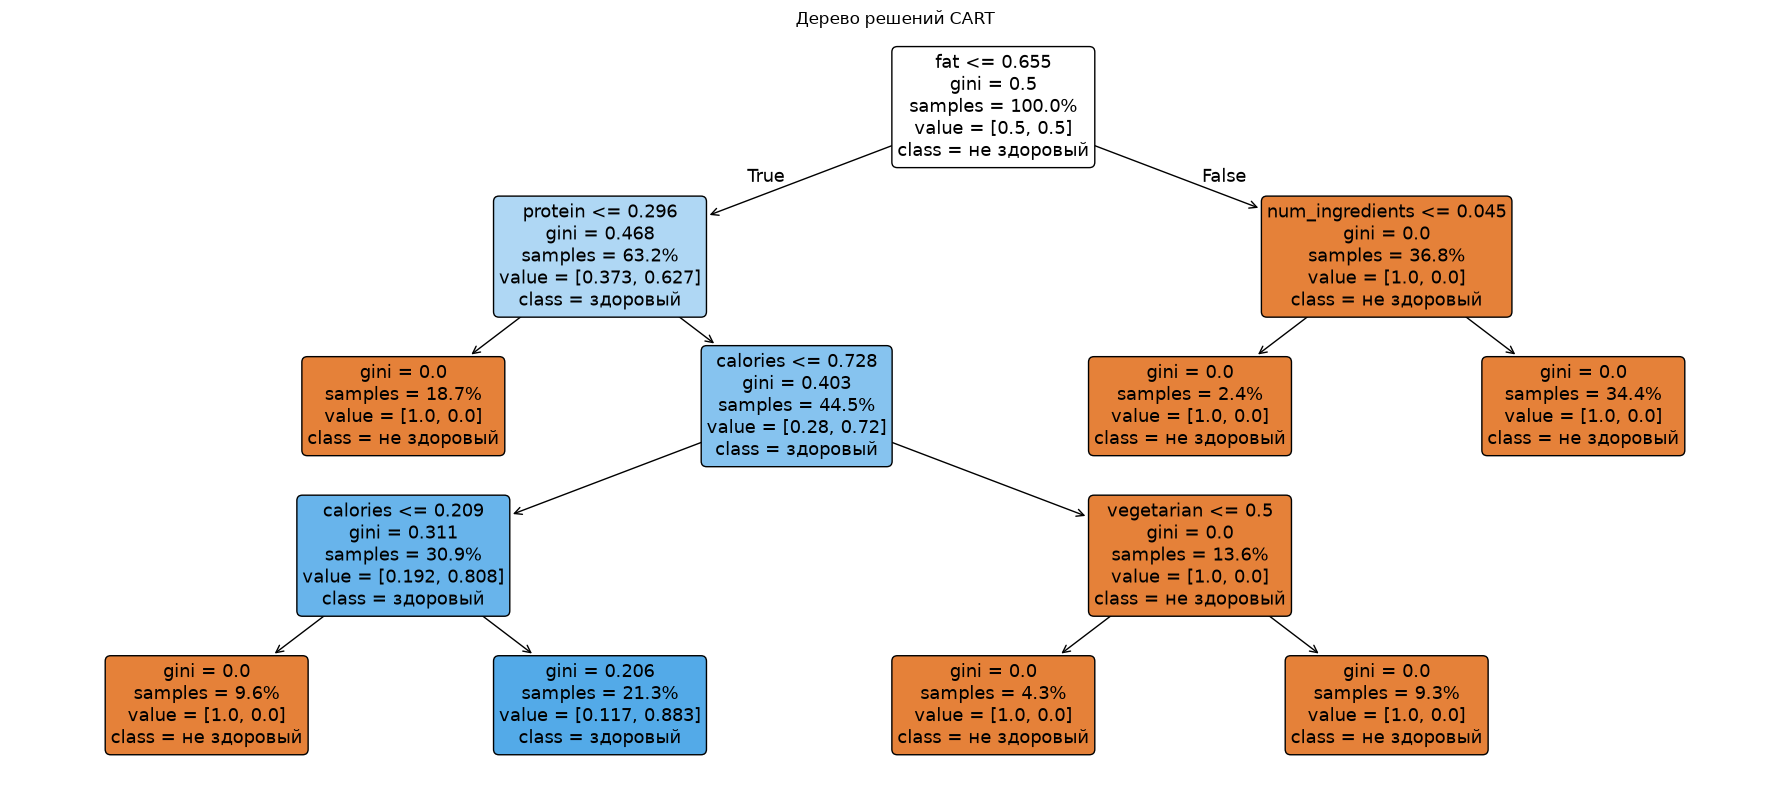

In [7]:
for name in models:
    print("\n", name)
    print(classification_report(y_test, predictions[name], zero_division=0, target_names=["не здоровый", "здоровый"]))

cart_model = models["CART"]
feature_importance = pd.Series(cart_model.feature_importances_, index=feature_columns).sort_values(ascending=False)
display(feature_importance.to_frame("importance"))

plt.figure(figsize=(18, 8))
plot_tree(cart_model, feature_names=feature_columns, class_names=["не здоровый", "здоровый"], filled=True, rounded=True, proportion=True)
plt.title("Дерево решений CART")
plt.tight_layout()
plt.show()

## 7. Выводы

Сравните модели по F1 и recall положительного класса, а также по матрицам ошибок. Укажите, какая модель лучше обнаруживает здоровые планы и какой компромисс возникает между precision и recall. Результаты вычисляются на тестовой выборке, которая не участвовала в обучении.

In [8]:
best_model = metrics.index[0]
print("Лучшая модель по F1 на тестовой выборке:", best_model)
print("F1:", round(metrics.loc[best_model, "F1"], 3))
print("Recall:", round(metrics.loc[best_model, "Recall"], 3))
print("Так как классы несбалансированы, вывод делается по нескольким метрикам, а не только по Accuracy.")

Лучшая модель по F1 на тестовой выборке: SVM
F1: 0.5
Recall: 0.833
Так как классы несбалансированы, вывод делается по нескольким метрикам, а не только по Accuracy.
